In [3]:
#Packages needed for the notebook
using CSV 
using Serialization 
using Revise 
using LinearAlgebra 
using Random 
using PyPlot 
using NaNStatistics 
using Statistics 
using ReverseDiff
using DataFrames
using Trapz
using Optim

### Including Files

In [4]:
function correct_path(splitted_path, String)
    """Function to retrieve files in a given path.
    It takes as input:
        1) splitted path: the current path split by each separator
        2) String: the path to reach the wanted file 
    The function returns:
        1) the correct complete path to reach the file
    """
    S="" #String initialization
    for i in 1:(length(splitted_path)-1)
        #Constructing the path with the correct separator and removing the last term
        S=S*splitted_path[i]*"/" 
    end
    #Final Output
    return S*String 
end

correct_path (generic function with 1 method)

In [5]:
#Including files with the functions
includet(correct_path(split(pwd(), '/'), "Functions/Variables and Structures.jl")) #For constant quantities or structures to save data
includet(correct_path(split(pwd(), '/'), "Functions/Inference.jl")) #For Training
includet(correct_path(split(pwd(), '/'), "Functions/Model Strategies and Testing.jl")) #For scoring testing datasets
includet(correct_path(split(pwd(), '/'), "Functions/Performance Indicator.jl")) #To compute performance over test datasets
includet(correct_path(split(pwd(), '/'), "Functions/Scaling Functions.jl")) #To compute MEMAR scaling and two-state state model

### Datasets

In [6]:
#Train,validation, prior from GLORI HEK293T (standard)
train=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Train_GLORI.bin")) 
validation=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Validation_GLORI.bin")) 
prior_HEK=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Prior_GLORI.bin")); 
"""Test sets for HEK293T"""
#Out-of sample: Control Condtions HEK293T with deep-sequencing
test_HEK=deserialize(correct_path(split(pwd(), '/'), "/Mapping/Data/HEK_CC_GLORI.bin"));
#Altered conditions HEK293T cell line
test_HEK_FTO=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HEK_FTO_GLORI.bin"))
test_HEK_STM2457=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HEK_STM2457_GLORI.bin"));
#Out-of sample: Control Condtions HeLa with deep-sequencing
test_HELA=deserialize(correct_path(split(pwd(), '/'), "/Mapping/Data/HELA_CC.bin"))
#Altered conditions HeLa cell line
test_HELA_siMETTL3=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_siMETTL3_GLORI.bin"));
test_HELA_siMETTL14=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_siMETTL14_GLORI.bin"))
test_HELA_siYTDH=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_siYTHDF2_GLORI.bin"))
test_HELA_HPX=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_Hypoxia_GLORI.bin"))
test_HELA_STM2457=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/HELA_STM2457_GLORI.bin"));


In [7]:
#Saving all the gene labels for the train, validation and prior
gene_train=keys(train)
gene_valid=keys(validation)
gene_prior_HEK=keys(prior_HEK);
#Saving test genes from unaltered conditions in both HEK293T and HeLa
gene_test_HEK=keys(test_HEK);
gene_HELA=keys(test_HELA);

A common set of genes is taken, consindering all transcripts with at least one methylated site in the unaltered conditions (excluding training and validating ones). 

In [8]:
#Finding genes not in the training, nor the validating, set considering HEK293T
gene_HEK_not_train=[]
[(haskey(train, a)==false && haskey(validation, a)==false ? push!(gene_HEK_not_train, a) : nothing ) for a in gene_test_HEK];

In [9]:
#To test genes I only keep those transcripts for which a proxy of the methylation abundancy is knwon
common_genes_HEK=intersect(vcat(gene_prior_HEK...),vcat(gene_HEK_not_train...)) # T̃ ∩ T 
genes_not_HEK=filtering_non_nucelotides(test_HEK)
#Removing a gene with non canonical nucleotide letterse
common_genes_HEK=setdiff(common_genes_HEK, genes_not_HEK); # T̃ ∩ T \ T_n 

The gene IPMK contain a (some) non-nucleotide(s) character(s) at position(s) [26] corresponding to the chacracter(s): N 
The gene PLCL2 contain a (some) non-nucleotide(s) character(s) at position(s) [3518] corresponding to the chacracter(s): W 


In [10]:
#Finding genes not in the training, nor the validating, set considering HeLa
gene_HELA_not_train=[]
[(haskey(train, a)==false && haskey(validation, a)==false ? push!(gene_HELA_not_train, a) : nothing) for a in gene_HELA];

In [11]:
#To test genes I only keep those transcripts for which a proxy of the methylation abundancy is knwon
common_genes_HELA=intersect(vcat(gene_prior_HEK...),vcat(gene_HELA_not_train...)) # T̃ ∩ T 
genes_not_HELA=filtering_non_nucelotides(test_HELA)
#Removing a gene with non canonical nucleotide letterse
common_genes_HELA=setdiff(common_genes_HELA, genes_not_HELA); # T̃ ∩ T \ T_n 

The gene RNA45SN2 contain a (some) non-nucleotide(s) character(s) at position(s) [11220] corresponding to the chacracter(s): N 
The gene IPMK contain a (some) non-nucleotide(s) character(s) at position(s) [26] corresponding to the chacracter(s): N 
The gene PLCL2 contain a (some) non-nucleotide(s) character(s) at position(s) [3518] corresponding to the chacracter(s): W 


In [12]:
#HEK293T
Test_HEK_FTO=copy_common_only(common_genes_HEK, test_HEK_FTO, test_HEK);
Test_HEK_STM2457=copy_common_only(common_genes_HEK, test_HEK_STM2457, test_HEK);
#HeLa
Test_HELA_HPX=copy_common_only(common_genes_HELA, test_HELA_HPX,test_HELA);
Test_HELA_STM2457=copy_common_only(common_genes_HELA, test_HELA_STM2457,test_HELA;)
Test_HELA_siMETTL3=copy_common_only(common_genes_HELA, test_HELA_siMETTL3, test_HELA);
Test_HELA_siMETTL14=copy_common_only(common_genes_HELA, test_HELA_siMETTL14, test_HELA);
Test_HELA_siYTDH=copy_common_only(common_genes_HELA, test_HELA_siYTDH, test_HELA);

### Training 

In [13]:
#Importing models trained on GLORI HEK293T
M5=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_met.bin")) # p(s̄|m)
M6=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/Model_not_met.bin")); # p(s̄|m̄)

### Prior definition

In [14]:
#Constant prior definition following the previous equations
Ava=[] #Initialization for the constant prior
[push!(Ava, train[a].perc_met) for a in gene_train];
Ava=mean(Ava) #p_0(m)
constant_prior=deepcopy(prior_HEK)
[constant_prior[a].perc_met=Ava for a in keys(constant_prior)];

In [15]:
#List of DRACH motifs
Dict_DRACH=Dict()
[Dict_DRACH[a]=[]  for a in DRACH];

### Mapping:

In [16]:
MAP_mRNA_HEK=mapping_position(test_HEK, vcat(common_genes_HEK...));
MAP_mRNA_HELA=mapping_position(test_HELA, vcat(common_genes_HELA...));

### Two-state model 

We address in this part the scaling of MEMAR model by a theoretical two-state dynamical model which describes the methylation process as a stochastich one, in which writers and ereasers can methylated or de-methylated a given site with a given probability. This probability will only depend parametrically on the statistics of 8-mers motifs. 


In [17]:
#Scoring all the 8-mers motifs
score_8mers=score_8_mers(M5, M6, Ava/100);
Dict_all8=Dict() #Initialization of a Dictionary
[Dict_all8[mots_list8[i][1:4]*'A'*mots_list8[i][5:8]]=score_8mers[i] for i in sortperm(score_8mers, rev=true)]; #Dictionary containing 

In [18]:
#Saving the probabilities into a dataframe
Df_Probability=DataFrame(Motifs=collect(keys(Dict_all8)), Probabilty=collect(values(Dict_all8))); 
#Ordering the dataframes in decreasing methylation proability
so=sortperm(Df_Probability[:, 2], rev=true);
Df_Probability[:, 1]=[Df_Probability[i,1] for i in so];
Df_Probability[:, 2]=[Df_Probability[i,2] for i in so];

In [19]:
#Scoring all DRACH motifs
score=score_DRACH(M5, M6, Dict_DRACH, Ava/100)
score_D=[score[DRACH[i][1:2]*DRACH[i][4:5]] for i in 1:length(DRACH)]
#Ordering DRACH motifs based on decreasing order of the methylation proabability
sort_D=sortperm(score_D, rev=true );
list_mots_D=DRACH[sort_D]; #ordered list of DRACH motifs

In [20]:
#Saving the probability of 8-mers DRACH motifs, the corresponding list in decresing order of methylation probability, 
#the position in the dataframe and the index of indexing for each 8-mers containing a DRACH motif following list_mots_D order 
p0, list_mots, pos, ind=probability_8DRACH(Df_Probability, Dict_DRACH, list_mots_D)
#Counting the amount of 8-mers DRACH motifs in the dataset, considering the common set of transcripts in control conditions
N_HEK_CC=[sum([count(b, test_HEK[a].sequence, overlap=true) for a in keys(MAP_mRNA_HEK)]) for b in list_mots];
N_HELA_CC=[sum([count(b, test_HELA[a].sequence, overlap=true) for a in keys(MAP_mRNA_HELA)]) for b in list_mots];

In [21]:
#We compute the predicted probability of marginalized DRACH motifs from the learnt model
p0_marg=score_D[sort_D];

In [22]:
#HEK293T
p_HEK_CC=eq_prob_MarG(test_HEK,train, list_mots_D);
p_HEK_STM=eq_prob_MarG(test_HEK_STM2457, train,list_mots_D);
p_HEK_FTO=eq_prob_MarG(test_HEK_FTO, train,list_mots_D);
#HeLa
p_HELA_CC=eq_prob_MarG(test_HELA, train,list_mots_D);
p_HELA_siMETTL3=eq_prob_MarG(test_HELA_siMETTL3, train,list_mots_D);
p_HELA_siMETTL14=eq_prob_MarG(test_HELA_siMETTL14, train,list_mots_D);
p_HELA_HPX=eq_prob_MarG(test_HELA_HPX, train,list_mots_D);
p_HELA_YTH=eq_prob_MarG(test_HELA_siYTDH, train,list_mots_D);
p_HELA_STM=eq_prob_MarG(test_HELA_STM2457, train,list_mots_D);

Converged at iteration 218, where the maximum error is 9.910296342921168e-6
Converged at iteration 135, where the maximum error is 9.767233934271195e-6
Converged at iteration 220, where the maximum error is 9.931400202461282e-6
Converged at iteration 125, where the maximum error is 9.737605862060288e-6
Converged at iteration 219, where the maximum error is 9.931663114061406e-6
Converged at iteration 138, where the maximum error is 9.895906598927657e-6
Converged at iteration 199, where the maximum error is 9.95136401693808e-6
Converged at iteration 149, where the maximum error is 9.911367647957685e-6
Converged at iteration 213, where the maximum error is 9.782703761337139e-6
Converged at iteration 133, where the maximum error is 9.838757399909144e-6
Converged at iteration 206, where the maximum error is 9.884149692430586e-6
Converged at iteration 136, where the maximum error is 9.77863103538432e-6
Converged at iteration 205, where the maximum error is 9.911867011851616e-6
Converged at i

In [78]:
#Amount of DRACH motifs amongst all 8-mers DRACH motifs, following the order of list_mots_D in HEK293T
N_DRACH_HEK=[sum(N_HEK_CC[ind[i]]) for i in 1:length(list_mots_D)];
#Amount of DRACH motifs amongst all 8-mers DRACH motifs, following the order of list_mots_D in HeLa
N_DRACH_HELA=[sum(N_HELA_CC[ind[i]]) for i in 1:length(list_mots_D)];
#Going back to the equilibrium curve
k_factor=1
#Equilibrium curve selecting a high value of time to mimic t->inf
time_dependence=10000000000
#Treshold choosen to compare the compatibility between MEMAR-C inferred in a given dataset and the uniform rescaled two-state model
tresh_c=[0.005,0.015,0.03];

### HEK293T 

In [24]:
#Computing the uniform-rescaling of the writer binding constant from inferred dataset to control conditions (obtained in deep sequecing)
x_opt_HEK_CC=Infer_uniform(p0_marg, p_HEK_CC, time_dependence);
#Initialzation 
MNU_HEK_CC, PNU_HEK_CC,PU_HEK_CC=[],[],[]
#Non uniform-rescaling
[push!(MNU_HEK_CC, [parameter_minimization(p0_marg, p_HEK_CC, time_dependence, i,j; xmin=0.01, pas=0.01, xmax=10) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the non-unfirom rescaling
[push!( PNU_HEK_CC, [parameter_p(p0_marg, time_dependence, i,j, MNU_HEK_CC) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HEK_CC, [parameter_p(p0_marg, time_dependence, i,j, x_opt_HEK_CC; verb=true) for j in 1:3]) for i in 1:18];

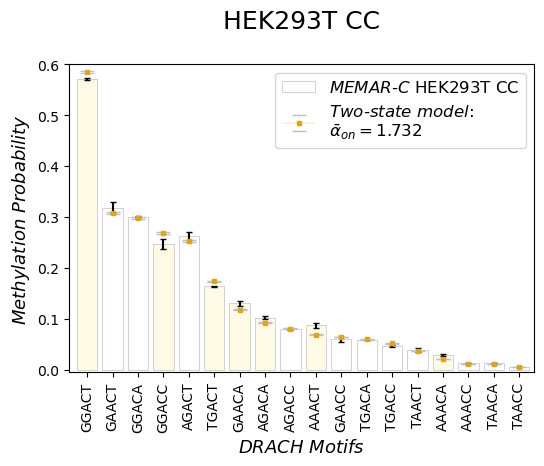

In [25]:
close("all")
figure(figsize=(6, 4))
title("HEK293T CC\n", size=18)
AA=explanation_degree_param(PU_HEK_CC, [[hcat(p_HEK_CC...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HEK_CC...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HEK_CC...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HEK_CC...)[i, j]) for j in 1:3]),  color="gold", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HEK_CC[i]),yerr=std(PU_HEK_CC[i]), marker="s", color="goldenrod", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HEK293T CC" )
errorbar("TTTTT",+21,1, marker="s", color="goldenrod", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(x_opt_HEK_CC)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.6)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

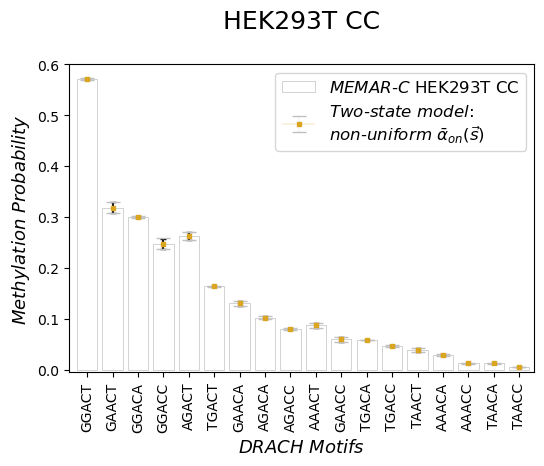

In [26]:
close("all")
figure(figsize=(6, 4))
title("HEK293T CC\n", size=18)
AA=explanation_degree_param(PNU_HEK_CC, [[hcat(p_HEK_CC...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HEK_CC...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HEK_CC...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10, lw=0.5) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HEK_CC...)[i, j]) for j in 1:3]),  color="gold", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PNU_HEK_CC[i]),yerr=std(PNU_HEK_CC[i]), marker="s", color="goldenrod", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
#scatter("GGACT", 100, marker="o",  s=20, edgecolor="silver", lw=0.3, color="rosybrown", alpha=1, zorder=20, label="Time-dependent Model:\n \$k_{on}^{STM2457}(\\vec{s})=\\alpha \\cdot  k_{on}^{CC}(\\vec{s}),  \\ \\alpha=\$ $(round(digits=3,  mean(x_opt_HEK_STM)))")
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,   label="\$MEMAR\$-\$C\$ HEK293T CC" )
errorbar("TTTTT",+21,1, marker="s", color="goldenrod", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$non\$-\$uniform\$ \$\\bar{\\alpha}_{on}({\\vec{s}})\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.6)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

### HeLa 

In [27]:
#Uniform-rescaling
HEK_to_HELA_CC=Infer_uniform(p0_marg, p_HELA_CC, time_dependence;F=MNU_HEK_CC);
#Initialization
MNU_HELA_CC, PNU_HELA_CC,PU_HELA_CC=[],[],[]
#Non-Uniform-rescaling
[push!(MNU_HELA_CC, [parameter_minimization(p0_marg, p_HELA_CC, time_dependence, i,j; xmin=0, F=MNU_HEK_CC, pas=0.00001, xmax=1.5) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the non-unfirom rescaling
[push!( PNU_HELA_CC, [parameter_p(p0_marg, time_dependence, i,j, MNU_HELA_CC; F=MNU_HEK_CC) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HELA_CC, [parameter_p(p0_marg, time_dependence, i,j, HEK_to_HELA_CC; F=MNU_HEK_CC,verb=true, ) for j in 1:3]) for i in 1:18];

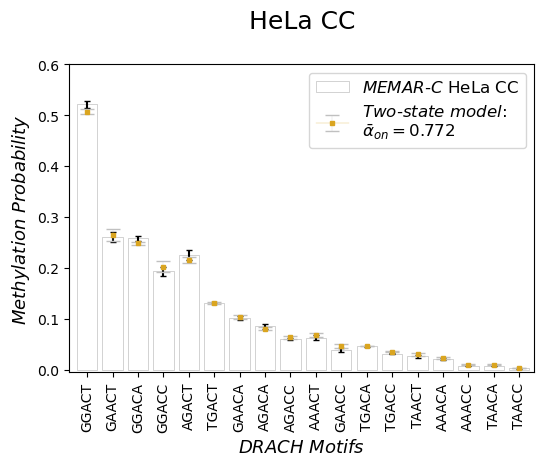

In [28]:
close("all")
figure(figsize=(6, 4))
title("HeLa CC\n", size=18)
AA=explanation_degree_param(PU_HELA_CC, [[hcat(p_HELA_CC...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HELA_CC...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HELA_CC...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HELA_CC...)[i, j]) for j in 1:3]),  color="gold", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HELA_CC[i]),yerr=std(PU_HELA_CC[i]), marker="s", color="goldenrod", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
#scatter("GGACT", 100, marker="o",  s=20, edgecolor="silver", lw=0.3, color="rosybrown", alpha=1, zorder=20, label="Time-dependent Model:\n \$k_{on}^{STM2457}(\\vec{s})=\\alpha \\cdot  k_{on}^{CC}(\\vec{s}),  \\ \\alpha=\$ $(round(digits=3,  mean(x_opt_HELA_STM)))")
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HeLa CC" )
errorbar("TTTTT",+21,1, marker="s", color="goldenrod", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3, label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HEK_to_HELA_CC)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.6)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

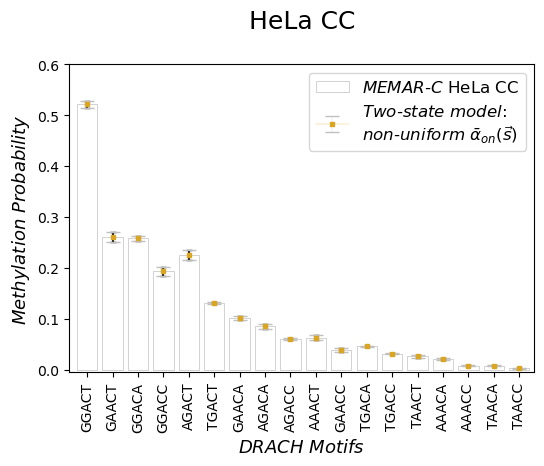

In [29]:
close("all")
figure(figsize=(6, 4))
title("HeLa CC\n", size=18)
AA=explanation_degree_param(PNU_HELA_CC, [[hcat(p_HELA_CC...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HELA_CC...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HELA_CC...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HELA_CC...)[i, j]) for j in 1:3]),  color="gold", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PNU_HELA_CC[i]),yerr=std(PNU_HELA_CC[i]), marker="s", color="goldenrod", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
#scatter("GGACT", 100, marker="o",  s=20, edgecolor="silver", lw=0.3, color="rosybrown", alpha=1, zorder=20, label="Time-dependent Model:\n \$k_{on}^{STM2457}(\\vec{s})=\\alpha \\cdot  k_{on}^{CC}(\\vec{s}),  \\ \\alpha=\$ $(round(digits=3,  mean(x_opt_HELA_STM)))")
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HeLa CC" )
errorbar("TTTTT",+21,1, marker="s", color="goldenrod", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$non\$-\$uniform\$ \$\\bar{\\alpha}_{on}({\\vec{s}})\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.6)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

### HeLa STM2457

In [30]:
#Uniform-rescaling
HELA_to_STM=Infer_uniform(p0_marg, p_HELA_STM, time_dependence; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18]);
#Initialization
MNU_HELA_STM,PNU_HELA_STM,PU_HELA_STM=[],[],[],[],[],[]
#Non-Uniform-rescaling
[push!(MNU_HELA_STM, [parameter_minimization(p0_marg, p_HELA_STM, time_dependence, i,j;  F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18], xmin=0.0,pas=0.00001, xmax=1.5) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the non-unfirom rescaling
[push!( PNU_HELA_STM, [parameter_p(p0_marg, time_dependence, i,j, MNU_HELA_STM; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18],) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HELA_STM, [parameter_p(p0_marg, time_dependence, i,j, HELA_to_STM; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18],verb=true) for j in 1:3]) for i in 1:18];

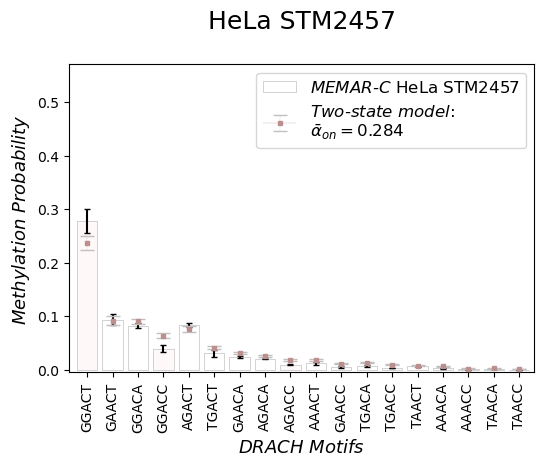

In [31]:
close("all")
figure(figsize=(6, 4))
title("HeLa STM2457\n", size=18)
AA=explanation_degree_param(PU_HELA_STM, [[hcat(p_HELA_STM...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HELA_STM...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HELA_STM...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HELA_STM...)[i, j]) for j in 1:3]),  color="pink", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HELA_STM[i]),yerr=std(PU_HELA_STM[i]), marker="s", color="rosybrown", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
#scatter("GGACT", 100, marker="o",  s=20, edgecolor="silver", lw=0.3, color="rosybrown", alpha=1, zorder=20, label="Time-dependent Model:\n \$k_{on}^{STM2457}(\\vec{s})=\\alpha \\cdot  k_{on}^{STM}(\\vec{s}),  \\ \\alpha=\$ $(round(digits=3,  mean(x_opt_HELA_STM)))")
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HeLa STM2457" )
errorbar("TTTTT",+21,1, marker="s", color="rosybrown", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HELA_to_STM)))\$ ")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

### HEK293T STM2457

In [32]:
#Uniform-rescaling
HEK_to_STM=Infer_uniform(p0_marg, p_HEK_STM, time_dependence;F=MNU_HEK_CC);
#Initialization
MNU_HEK_STM, PNU_HEK_STM,PU_HEK_STM=[],[],[],[],[],[]
#Non-Uniform-rescaling
[push!(MNU_HEK_STM, [parameter_minimization(p0_marg, p_HEK_STM, time_dependence, i,j; xmin=0.0, F=MNU_HEK_CC, pas=0.00001, xmax=1.5) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the non-unfirom rescaling
[push!( PNU_HEK_STM, [parameter_p(p0_marg, time_dependence, i,j, MNU_HEK_STM; F=MNU_HEK_CC,) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HEK_STM, [parameter_p(p0_marg, time_dependence, i,j, HEK_to_STM; F=MNU_HEK_CC, verb=true) for j in 1:3]) for i in 1:18];

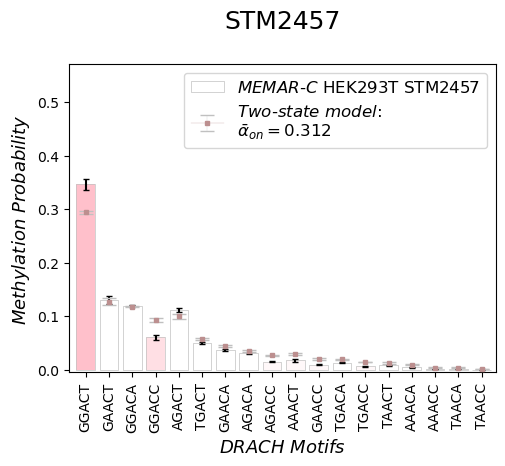

In [33]:
close("all")
figure(figsize=(5.5, 4))
title("STM2457\n", size=18)
AA=explanation_degree_param(PU_HEK_STM, [[hcat(p_HEK_STM...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HEK_STM...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HEK_STM...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HEK_STM...)[i, j]) for j in 1:3]),  color="pink", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HEK_STM[i]),yerr=std(PU_HEK_STM[i]), marker="s", color="rosybrown", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
#scatter("GGACT", 100, marker="o",  s=20, edgecolor="silver", lw=0.3, color="rosybrown", alpha=1, zorder=20, label="Time-dependent Model:\n \$k_{on}^{STM2457}(\\vec{s})=\\alpha \\cdot  k_{on}^{STM}(\\vec{s}),  \\ \\alpha=\$ $(round(digits=3,  mean(x_opt_HEK_STM)))")
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HEK293T STM2457" )
errorbar("TTTTT",+21,1, marker="s", color="rosybrown", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3, label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HEK_to_STM)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

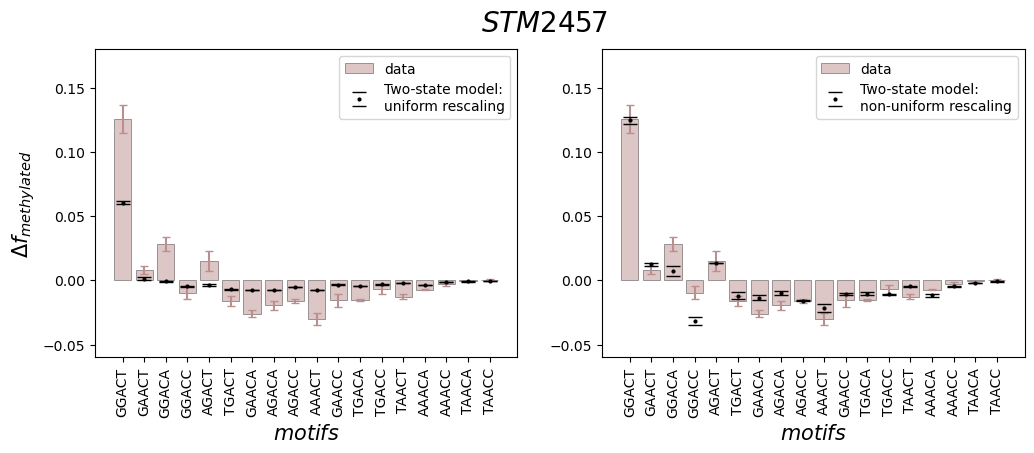

In [80]:
D_M_STM, D_S_STM=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/DeltaF_STM2457.bin"))
LP, LLP=s_a_f(N_DRACH_HEK, PU_HEK_STM, PNU_HEK_CC);
close("all")
figure(figsize=(12, 4))
suptitle(L"STM2457", size=20)
subplot(1,2, 1)
bar(vcat(1:length(list_mots_D)...),  D_M_STM, yerr=D_S_STM,  capsize=3, color="rosybrown", ecolor="rosybrown", edgecolor="black", lw=0.5, alpha=0.5, label="data")
errorbar(vcat(1:length(list_mots_D)...), LP, yerr=LLP,  capsize=5, color="black", fmt="o", lw=0.05, markersize=2, label="Two-state model:\nuniform rescaling")
xticks(vcat(1:length(list_mots_D)...), list_mots_D, rotation=90)
ylabel(L"\Delta f_{methylated}", size=15)
xlabel(L"motifs", size=15)
legend()
ylim(-0.06, 0.18)
subplot(1,2, 2)
LP, LLP=s_a_f(N_DRACH_HEK, PNU_HEK_STM, PNU_HEK_CC);
bar(vcat(1:length(list_mots_D)...),  D_M_STM, yerr=D_S_STM,  capsize=3, color="rosybrown", ecolor="rosybrown", edgecolor="black", lw=0.5, alpha=0.5, label="data")
errorbar(vcat(1:length(list_mots_D)...), LP, yerr=LLP,  capsize=5, color="black", fmt="o", lw=0.05, markersize=2, label="Two-state model:\nnon-uniform rescaling")
xticks(vcat(1:length(list_mots_D)...), list_mots_D, rotation=90)
xlabel(L"motifs", size=15)
legend()
ylim(-0.06, 0.18)
gcf()

### HeLa Hypoxia

In [35]:
#Uniform-rescaling
HELA_to_HPX=Infer_uniform(p0_marg, p_HELA_HPX, time_dependence; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18]);
#Initialization
MNU_HELA_HPX, PNU_HELA_HPX,PU_HELA_HPX=[],[],[]
[push!(MNU_HELA_HPX, [parameter_minimization(p0_marg, p_HELA_HPX, time_dependence, i,j;  F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18], xmin=0.0,pas=0.00001, xmax=1.5) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the non-unfirom rescaling
[push!( PNU_HELA_HPX, [parameter_p(p0_marg, time_dependence, i,j, MNU_HELA_HPX; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18],) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HELA_HPX, [parameter_p(p0_marg, time_dependence, i,j, HELA_to_HPX; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18],verb=true) for j in 1:3]) for i in 1:18];

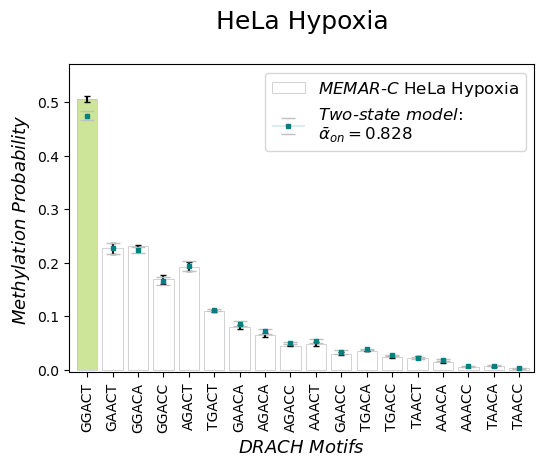

In [36]:
close("all")
figure(figsize=(6, 4))
title("HeLa Hypoxia\n", size=18)
AA=explanation_degree_param(PU_HELA_HPX, [[hcat(p_HELA_HPX...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HELA_HPX...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HELA_HPX...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HELA_HPX...)[i, j]) for j in 1:3]),  color="yellowgreen", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HELA_HPX[i]),yerr=std(PU_HELA_HPX[i]), marker="s", color="teal", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
#scatter("GGACT", 100, marker="o",  s=20, edgecolor="silver", lw=0.3, color="teal", alpha=1, zorder=20, label="Time-dependent Model:\n \$k_{on}^{HPX2457}(\\vec{s})=\\alpha \\cdot  k_{on}^{HPX}(\\vec{s}),  \\ \\alpha=\$ $(round(digits=3,  mean(x_opt_HELA_HPX)))")
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HeLa Hypoxia")
errorbar("TTTTT",+21,1, marker="s", color="teal", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HELA_to_HPX)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

### HeLa siYTHDF2

In [37]:
#Uniform-rescaling
HELA_to_YTH=Infer_uniform(p0_marg, p_HELA_YTH, time_dependence; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18]);
#Initialization
MNU_HELA_YTH, LU_HELA_YTH, DLU_HELA_YTH, STD_HELA_YTH,PNU_HELA_YTH,PU_HELA_YTH=[],[],[],[],[],[]
#Non-uiform rescaling
[push!(MNU_HELA_YTH, [parameter_minimization(p0_marg, p_HELA_YTH, time_dependence, i,j;  F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18], xmin=0.0,pas=0.00001, xmax=1.5) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the non-unfirom rescaling
[push!( PNU_HELA_YTH, [parameter_p(p0_marg, time_dependence, i,j, MNU_HELA_YTH; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18],) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HELA_YTH, [parameter_p(p0_marg, time_dependence, i,j, HELA_to_YTH; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18],verb=true) for j in 1:3]) for i in 1:18];

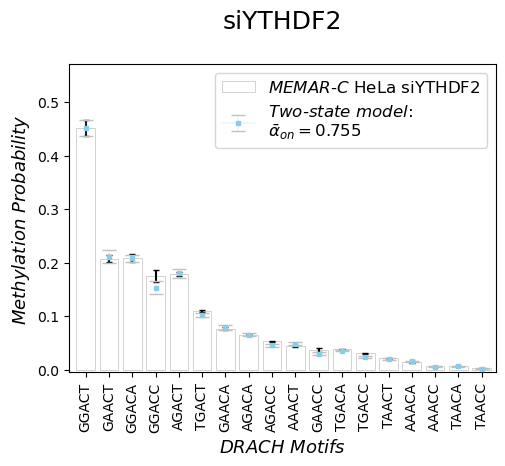

In [38]:
close("all")
figure(figsize=(5.5, 4))
title("siYTHDF2\n", size=18)
AA=explanation_degree_param(PU_HELA_YTH, [[hcat(p_HELA_YTH...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HELA_YTH...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HELA_YTH...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HELA_YTH...)[i, j]) for j in 1:3]),  color="powderblue", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HELA_YTH[i]),yerr=std(PU_HELA_YTH[i]), marker="s", color="skyblue", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
#scatter("GGACT", 100, marker="o",  s=20, edgecolor="silver", lw=0.3, color="skyblue", alpha=1, zorder=20, label="Time-dependent Model:\n \$k_{on}^{YTH2457}(\\vec{s})=\\alpha \\cdot  k_{on}^{YTH}(\\vec{s}),  \\ \\alpha=\$ $(round(digits=3,  mean(x_opt_HELA_YTH)))")
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HeLa siYTHDF2" )
errorbar("TTTTT",+21,1, marker="s", color="skyblue", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HELA_to_YTH)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

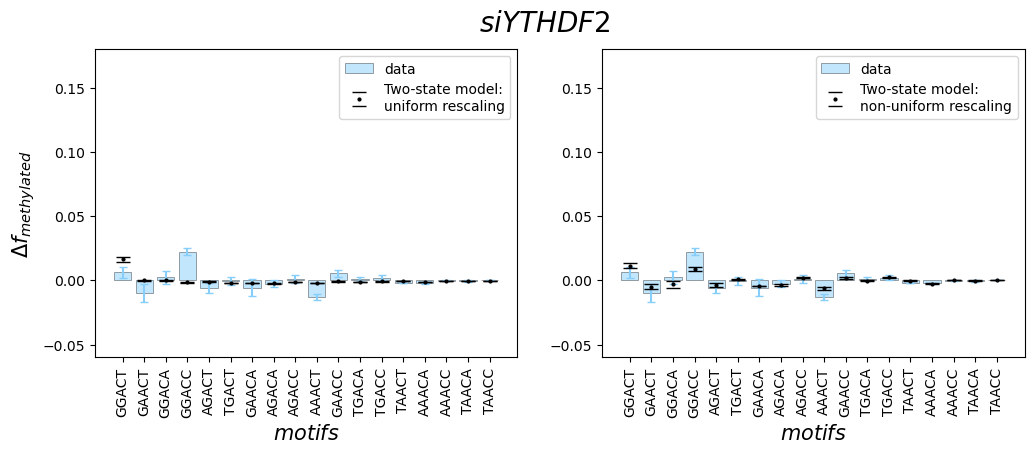

In [81]:
D_M_YTH, D_S_YTH=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/DeltaF_siYTHDF2.bin"))

LP, LLP=s_a_f(N_DRACH_HELA, PU_HELA_YTH, PNU_HELA_CC);
close("all")
figure(figsize=(12, 4))
suptitle(L"siYTHDF2", size=20)
subplot(1,2, 1)
bar(vcat(1:length(list_mots_D)...),  D_M_YTH, yerr=D_S_YTH,  capsize=3, color="lightskyblue", ecolor="lightskyblue", edgecolor="black", lw=0.5, alpha=0.5, label="data")
errorbar(vcat(1:length(list_mots_D)...), LP, yerr=LLP,  capsize=5, color="black", fmt="o", lw=0.05, markersize=2, label="Two-state model:\nuniform rescaling")
xticks(vcat(1:length(list_mots_D)...), list_mots_D, rotation=90)
ylabel(L"\Delta f_{methylated}", size=15)
xlabel(L"motifs", size=15)
legend()
ylim(-0.06, 0.18)
subplot(1,2, 2)
LP, LLP=s_a_f(N_DRACH_HELA, PNU_HELA_YTH, PNU_HELA_CC);
bar(vcat(1:length(list_mots_D)...),  D_M_YTH, yerr=D_S_YTH,  capsize=3, color="lightskyblue", ecolor="lightskyblue", edgecolor="black", lw=0.5, alpha=0.5, label="data")
errorbar(vcat(1:length(list_mots_D)...), LP, yerr=LLP,  capsize=5, color="black", fmt="o", lw=0.05, markersize=2, label="Two-state model:\nnon-uniform rescaling")
xticks(vcat(1:length(list_mots_D)...), list_mots_D, rotation=90)
xlabel(L"motifs", size=15)
legend()
ylim(-0.06, 0.18)
gcf()

### HeLa siYTHDF2

In [40]:
#Uniform-rscaling
HELA_to_siMETTL3=Infer_uniform(p0_marg, p_HELA_siMETTL3, time_dependence; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18]);
#Initialization
MNU_HELA_siMETTL3, LU_HELA_siMETTL3, DLU_HELA_siMETTL3, STD_HELA_siMETTL3,PNU_HELA_siMETTL3,PU_HELA_siMETTL3=[],[],[],[],[],[]
[push!(MNU_HELA_siMETTL3, [parameter_minimization(p0_marg, p_HELA_siMETTL3, time_dependence, i,j;  F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18], xmin=0.0,pas=0.00001, xmax=1.5) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the non-unfirom rescaling
[push!( PNU_HELA_siMETTL3, [parameter_p(p0_marg, time_dependence, i,j, MNU_HELA_siMETTL3; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18],) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HELA_siMETTL3, [parameter_p(p0_marg, time_dependence, i,j, HELA_to_siMETTL3; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18],verb=true) for j in 1:3]) for i in 1:18];

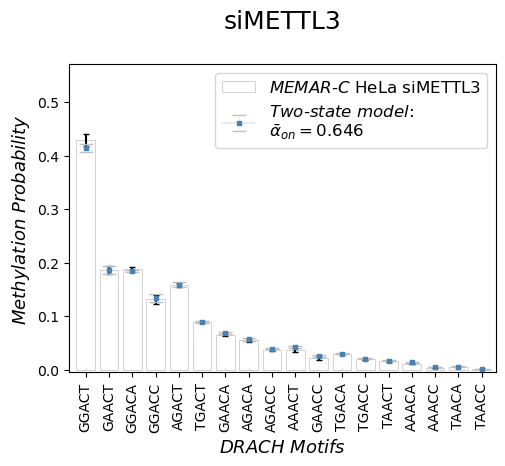

In [41]:
close("all")
figure(figsize=(5.5, 4))
title("siMETTL3\n", size=18)
AA=explanation_degree_param(PU_HELA_siMETTL3, [[hcat(p_HELA_siMETTL3...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HELA_siMETTL3...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HELA_siMETTL3...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HELA_siMETTL3...)[i, j]) for j in 1:3]),  color="skyblue", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HELA_siMETTL3[i]),yerr=std(PU_HELA_siMETTL3[i]), marker="s", color="steelblue", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
#scatter("GGACT", 100, marker="o",  s=20, edgecolor="silver", lw=0.3, color="steelblue", alpha=1, zorder=20, label="Time-dependent Model:\n \$k_{on}^{siMETTL32457}(\\vec{s})=\\alpha \\cdot  k_{on}^{siMETTL3}(\\vec{s}),  \\ \\alpha=\$ $(round(digits=3,  mean(x_opt_HELA_siMETTL3)))")
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HeLa siMETTL3" )
errorbar("TTTTT",+21,1, marker="s", color="steelblue", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HELA_to_siMETTL3)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

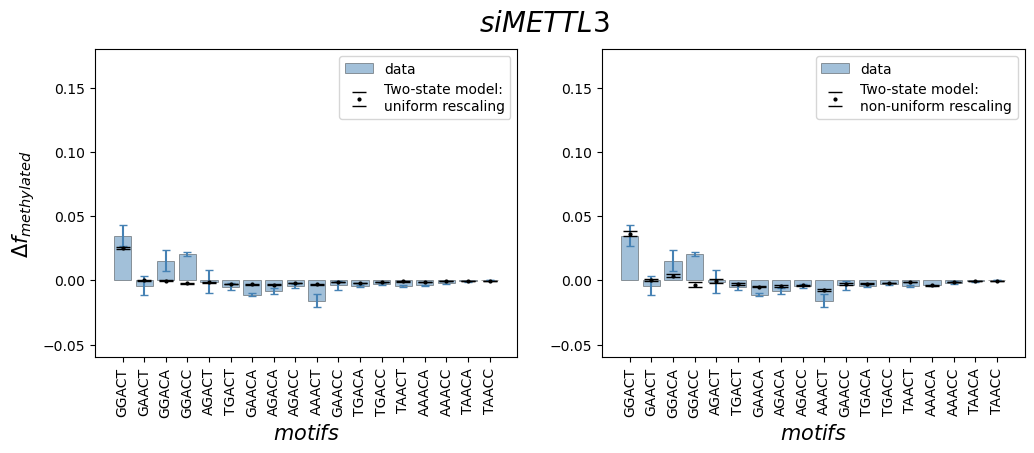

In [82]:
D_M_MET3, D_S_MET3=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/DeltaF_siMETTL3.bin"))
LP, LLP=s_a_f(N_DRACH_HELA, PU_HELA_siMETTL3, PNU_HELA_CC);
close("all")
figure(figsize=(12, 4))
suptitle(L"siMETTL3", size=20)
subplot(1,2, 1)
bar(vcat(1:length(list_mots_D)...),  D_M_MET3, yerr=D_S_MET3,  capsize=3, color="steelblue", ecolor="steelblue", edgecolor="black", lw=0.5, alpha=0.5, label="data")
errorbar(vcat(1:length(list_mots_D)...), LP, yerr=LLP,  capsize=5, color="black", fmt="o", lw=0.05, markersize=2, label="Two-state model:\nuniform rescaling")
xticks(vcat(1:length(list_mots_D)...), list_mots_D, rotation=90)
ylabel(L"\Delta f_{methylated}", size=15)
xlabel(L"motifs", size=15)
legend()
ylim(-0.06, 0.18)
subplot(1,2, 2)
LP, LLP=s_a_f(N_DRACH_HELA, PNU_HELA_siMETTL3, PNU_HELA_CC);
bar(vcat(1:length(list_mots_D)...),  D_M_MET3, yerr=D_S_MET3,  capsize=3, color="steelblue", ecolor="steelblue", edgecolor="black", lw=0.5, alpha=0.5, label="data")
errorbar(vcat(1:length(list_mots_D)...), LP, yerr=LLP,  capsize=5, color="black", fmt="o", lw=0.05, markersize=2, label="Two-state model:\nnon-uniform rescaling")
xticks(vcat(1:length(list_mots_D)...), list_mots_D, rotation=90)
xlabel(L"motifs", size=15)
legend()
ylim(-0.06, 0.18)
gcf()

### HeLa siMETTL3

In [43]:
#Uniform Rescaling
HELA_to_siMETTL14=Infer_uniform(p0_marg, p_HELA_siMETTL14, time_dependence; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18]);
#Initialization
MNU_HELA_siMETTL14, PNU_HELA_siMETTL14,PU_HELA_siMETTL14=[],[],[]
#Non-uniform Rescaling
[push!(MNU_HELA_siMETTL14, [parameter_minimization(p0_marg, p_HELA_siMETTL14, time_dependence, i,j;  F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18], xmin=0.0,pas=0.00001, xmax=1.5) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the non-unfirom rescaling
[push!( PNU_HELA_siMETTL14, [parameter_p(p0_marg, time_dependence, i,j, MNU_HELA_siMETTL14; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18],) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HELA_siMETTL14, [parameter_p(p0_marg, time_dependence, i,j, HELA_to_siMETTL14; F=[MNU_HEK_CC[i].*MNU_HELA_CC[i] for i in 1:18],verb=true) for j in 1:3]) for i in 1:18];

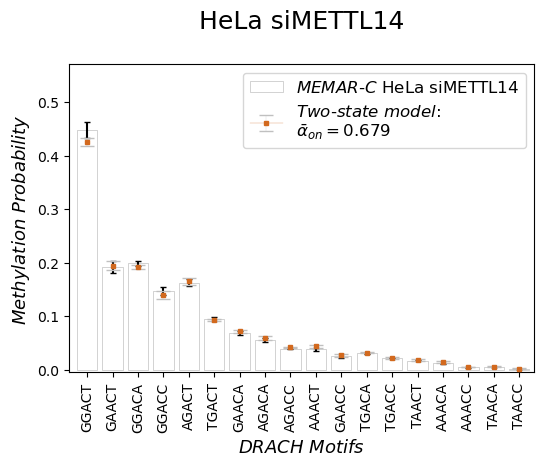

In [44]:
close("all")
figure(figsize=(6, 4))
title("HeLa siMETTL14\n", size=18)
AA=explanation_degree_param(PU_HELA_siMETTL14, [[hcat(p_HELA_siMETTL14...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HELA_siMETTL14...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HELA_siMETTL14...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HELA_siMETTL14...)[i, j]) for j in 1:3]),  color="sandybrown", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HELA_siMETTL14[i]),yerr=std(PU_HELA_siMETTL14[i]), marker="s", color="chocolate", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
#scatter("GGACT", 100, marker="o",  s=20, edgecolor="silver", lw=0.3, color="chocolate", alpha=1, zorder=20, label="Time-dependent Model:\n \$k_{on}^{siMETTL142457}(\\vec{s})=\\alpha \\cdot  k_{on}^{siMETTL14}(\\vec{s}),  \\ \\alpha=\$ $(round(digits=3,  mean(x_opt_HELA_siMETTL14)))")
bar("TTTTT",+21,   edgecolor="silver", color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label=label="\$MEMAR\$-\$C\$ HeLa siMETTL14" )
errorbar("TTTTT",+21,1, marker="s", color="chocolate", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{on}=$(round(digits=3, mean(HELA_to_siMETTL14)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

### HEK293T FTO 

In [45]:
#Uniform-rescaling
HEK_to_FTO=Infer_uniform_FTO(p0_marg, p_HEK_FTO, time_dependence;F=MNU_HEK_CC);
#Initialization
MNU_HEK_FTO,PNU_HEK_FTO,PU_HEK_FTO=[],[],[]
#Non-Uniform Rescaling
[push!(MNU_HEK_FTO, [parameter_minimization_FTO(p0_marg, p_HEK_FTO, time_dependence, i,j; xmin=1.0, F=MNU_HEK_CC, pas=0.01, xmax=100) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the non-unfirom rescaling
[push!( PNU_HEK_FTO, [parameter_p_FTO(p0_marg, time_dependence, i,j, MNU_HEK_FTO; F=MNU_HEK_CC,) for j in 1:3]) for i in 1:18];
#Saving predicted probabilities o the two-state model after the unfirom rescaling
[push!( PU_HEK_FTO, [parameter_p_FTO(p0_marg, time_dependence, i,j, HEK_to_FTO; F=MNU_HEK_CC, verb=true) for j in 1:3]) for i in 1:18];

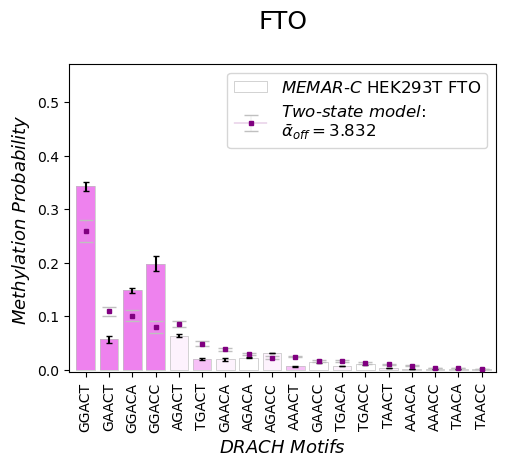

In [46]:
close("all")
figure(figsize=(5.5, 4))
title("FTO\n", size=18)
AA=explanation_degree_param(PU_HEK_FTO, [[hcat(p_HEK_FTO...)[i, j] for j in 1:3] for i in 1:18])
[bar(list_mots_D[i],mean([(hcat(p_HEK_FTO...)[i, j]) for j in 1:3]), yerr= std([(hcat(p_HEK_FTO...)[i, j]) for j in 1:3]),  color=[0,0,0,0], edgecolor="silver", capsize=2, zorder=10,  lw=0.5, ) for i in 1:18]
[bar(list_mots_D[i],mean([(hcat(p_HEK_FTO...)[i, j]) for j in 1:3]),  color="violet", zorder=1, alpha=AA[i], ) for i in 1:18]
[errorbar(list_mots_D[i],mean(PU_HEK_FTO[i]),yerr=std(PU_HEK_FTO[i]), marker="s", color="purple", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3) for i in 1:18]
#scatter("GGACT", 100, marker="o",  s=20, edgecolor="silver", lw=0.3, color="purple", alpha=1, zorder=20, label="Time-dependent Model:\n \$k_{on}^{FTO2457}(\\vec{s})=\\alpha \\cdot  k_{on}^{FTO}(\\vec{s}),  \\ \\alpha=\$ $(round(digits=3,  mean(x_opt_HEK_FTO)))")
bar("TTTTT",+21,   edgecolor="silver",  color=[0,0,0,0], capsize=0,  lw=0.5, zorder=1,  label="\$MEMAR\$-\$C\$ HEK293T FTO")
errorbar("TTTTT",+21,1, marker="s", color="purple", lw=0.2, ecolor="silver", zorder=20,capsize=5, markersize=3,label="\$Two\$-\$state\$ \$model\$:\n\$\\bar{\\alpha}_{off}=$(round(digits=3, mean(HEK_to_FTO)))\$")
xlabel(L"DRACH \ Motifs", size=13)
ylabel(L"Methylation \ Probability", size=13)
xticks(rotation=90)
ylim(-0.005, 0.57)
xlim(-0.7, 17.6)
legend(fontsize=12)
xticks(rotation=90)
gcf()

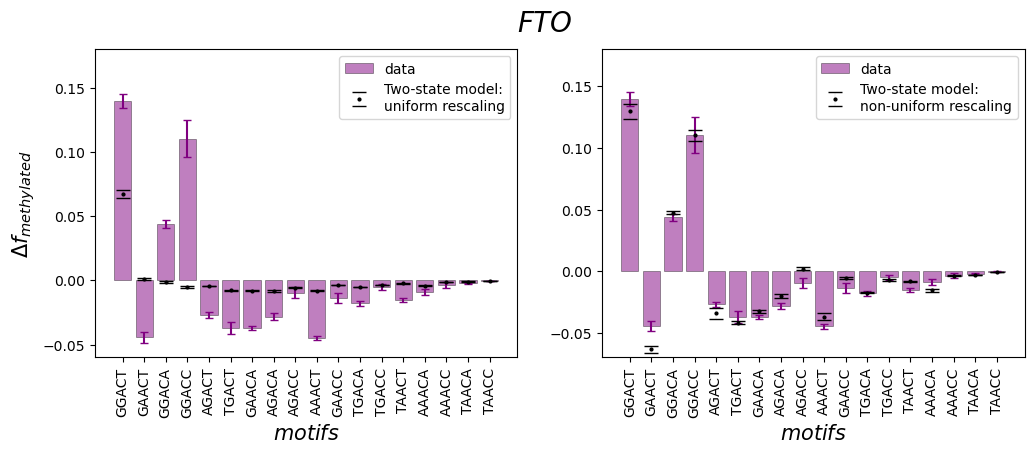

In [83]:
D_M_FTO, D_S_FTO=deserialize(correct_path(split(pwd(), '/'), "Mapping/Data/DeltaF_FTO.bin"))
LP, LLP=s_a_f(N_DRACH_HEK, PU_HEK_FTO, PNU_HEK_CC);
close("all")
figure(figsize=(12, 4))
suptitle(L"FTO", size=20)
subplot(1,2, 1)
bar(vcat(1:length(list_mots_D)...),  D_M_FTO, yerr=D_S_FTO,  capsize=3, color="purple", ecolor="purple", edgecolor="black", lw=0.5, alpha=0.5, label="data")
errorbar(vcat(1:length(list_mots_D)...), LP, yerr=LLP,  capsize=5, color="black", fmt="o", lw=0.05, markersize=2, label="Two-state model:\nuniform rescaling")
xticks(vcat(1:length(list_mots_D)...), list_mots_D, rotation=90)
ylabel(L"\Delta f_{methylated}", size=15)
xlabel(L"motifs", size=15)
legend()
ylim(-0.06, 0.18)
subplot(1,2, 2)
LP, LLP=s_a_f(N_DRACH_HEK, PNU_HEK_FTO, PNU_HEK_CC);
bar(vcat(1:length(list_mots_D)...),  D_M_FTO, yerr=D_S_FTO,  capsize=3, color="purple", ecolor="purple", edgecolor="black", lw=0.5, alpha=0.5, label="data")
errorbar(vcat(1:length(list_mots_D)...), LP, yerr=LLP,  capsize=5, color="black", fmt="o", lw=0.05, markersize=2, label="Two-state model:\nnon-uniform rescaling")
xticks(vcat(1:length(list_mots_D)...), list_mots_D, rotation=90)
xlabel(L"motifs", size=15)
legend()
ylim(-0.07, 0.18)
gcf()